# Project 02 · Callable Bond Pricing & Swap Hedging


> **Reproducibility:** All values are simulated or assumed; these are educational pricing and risk-management demonstrations, not production trade recommendations. Re-run the cells from top to bottom.

> **How to run:** Open from the repository root (or `notebooks/`); the first code cell configures the engine import path. Install packages with `pip install -r requirements.txt`.


In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'engines').exists():
    root = root.parent
assert (root / 'engines').exists(), 'Launch Jupyter from the repository root or notebooks folder'
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize':(10,4.5),'axes.grid':True})


## Trading mandate and market conventions

**Source:** `SPOILER_Project_FICC.html`, **Exotic Trader: Pricing and Managing a Callable Bond**.

- **10-year**, **$100 par**, **5% annual coupon paid semiannually**.
- Issuer has a **par call at year 5** immediately after the coupon.
- Starting zero curve: **1-year 2.0%**, **5-year 2.5%**, **10-year 3.0%**, with linear interpolation in zero rates.
- A **63-trading-day (one quarter)** simulated rate path; model the swap hedge and resulting bond P&L.

**Model enhancement vs the brief:** rather than naively using `min(noncallable price, value assuming a year-5 call)`, we use a **state-dependent issuer exercise decision** on a calibrated recombining short-rate tree. This adds time-value to the issuer's call option and gives an internally consistent single-call-date price. The example is educational, not a full Hull–White calibration to a swaptions surface.

In [2]:
from engines.models import callable_bond, bond_risk, simulate_callable
curve={1.:.02,5.:.025,10.:.03}
mark=callable_bond(curve,coupon=5.,maturity=10.,call_at=5.,sigma_r=.012)
risk=bond_risk(curve,coupon=5.,sigma_r=.012)
print('Callable bond clean model price per 100 face:',round(mark['price'],4))
print('Noncallable bond price:',round(mark['noncall_price'],4))
print('Issuer call value:',round(mark['option_value'],4))
print('Yield to maturity:',f"{mark['ytm']:.3%}")
print('Yield to call (assumes call at year 5):',f"{mark['ytc']:.3%}")
print('DV01 per 100 face:',round(risk['dv01'],5))
print('Modified duration:',round(risk['modified_duration'],3))

Callable bond clean model price per 100 face: 109.6197
Noncallable bond price: 117.7035
Issuer call value: 8.0839
Yield to maturity: 3.833%
Yield to call (assumes call at year 5): 2.918%
DV01 per 100 face: 0.06239
Modified duration: 5.691


## Pricing methodology

For a noncallable coupon bond, \(P_\mathrm{straight}=\sum_{i=1}^{20} CF_i D(0,t_i)\). The callable price is \(P_\mathrm{callable}=P_\mathrm{straight}-V_\mathrm{issuer\ call}\), where the value of the issuer option is nonnegative.

We calibrate a **recombining additive short-rate lattice** with \(r_{n,j}=a_n+\sigma_r\sqrt{\Delta t}(2j-n)\). The time-dependent \(a_n\) ensures the lattice exactly reproduces each interpolated zero-curve discount factor. At the year-5 node, issuer exercise truncates the investor's remaining value at par: \(V_{5,j}=c+\min(100,\mathrm{continuation}_{5,j})\). Elsewhere, add the coupon and discount the expected continuation.

**Risk:** bump *all* curve pillars by ±1 bp for callable-bond DV01. This captures rate sensitivity and exercise behavior through repricing; it is not a key-rate risk vector.

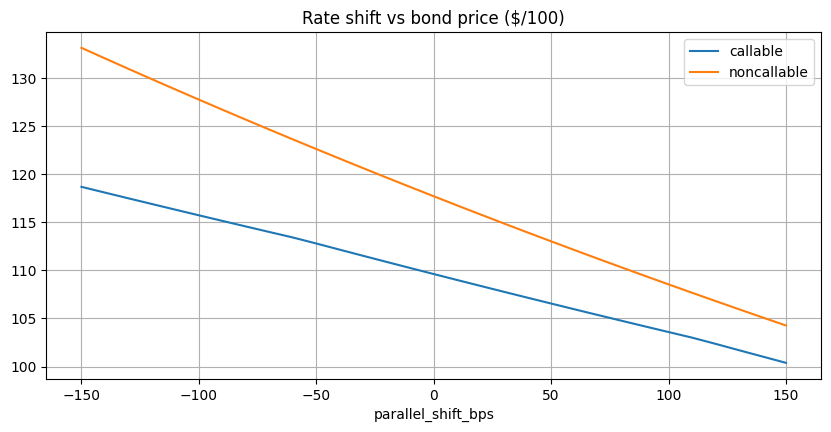

In [3]:
steps=np.arange(-150,151,10)
scenario=[]
for bp in steps:
    shifted={t:max(.0001,y+bp/10000) for t,y in curve.items()}
    m=callable_bond(shifted,coupon=5.,sigma_r=.012)
    scenario.append({'parallel_shift_bps':bp,'callable':m['price'],'noncallable':m['noncall_price']})
scenario=pd.DataFrame(scenario)
scenario.plot(x='parallel_shift_bps',y=['callable','noncallable'],title='Rate shift vs bond price ($/100)');plt.show()

## Swap hedging over 63 days

The desk is **long $1 million face value** of callable bond and hedges with a **pay-fixed, receive-floating five-year par swap**. A positive rate move causes a loss on the bond and a gain on the pay-fixed swap. Day-0 swap notional is chosen to match dollar DV01:

\[N_\mathrm{swap} = \frac{\mathrm{DV01}_\mathrm{bond}}{A_{5y}\times10^{-4}},\quad A_{5y}=\sum_{k=1}^{10}0.5D(0,k/2).\]

Each day the short-rate tree is recalibrated to the new parallel-shifted curve. Daily bond change + swap gain (first-order par-rate approximation using **y(5)** as proxy) minus turnover charges gives the *net* hedge P&L.

**Limitations:** no swap carry, term-structure reshaping, financing, credit/liquidity spread or issuer-specific default correlation; these matter in production.

,day,rate_5y,callable_price,bond_dv01_usd,swap_notional,bond_pnl,swap_pnl,hedged_pnl
0,0,0.025,109.620,623.878,1328824.065,0.000,0.000,-33.221
1,1,0.025,109.508,623.108,1327827.377,-1118.463,1118.612,-33.096
2,2,0.026,109.038,619.880,1323641.022,-4694.371,4697.000,-30.572
3,3,0.025,109.594,623.699,1328593.071,5553.589,-5549.903,-27.009
4,4,0.026,109.069,620.092,1323916.842,-5244.471,5247.751,-23.847
5,5,0.026,109.084,620.193,1324047.747,146.717,-146.715,-23.848
6,6,0.025,109.332,621.901,1326263.406,2484.120,-2483.383,-23.165
7,7,0.025,109.582,623.621,1328492.038,2500.249,-2499.504,-22.476
8,8,0.025,109.921,625.949,1331504.944,3382.633,-3381.271,-21.189
9,9,0.024,109.991,626.431,1332128.309,700.222,-700.164,-21.146


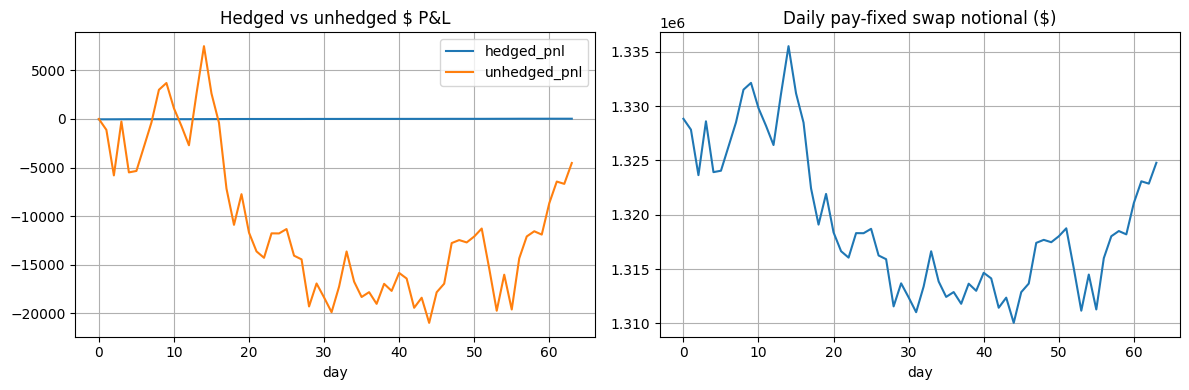

Net hedged P&L: 29.04
Unhedged P&L: -4537.31
Execution costs: 36.65


In [4]:
hedge=simulate_callable(days=63,face=1_000_000,seed=21,sigma_r=.012,
    daily_shift_bps=5.,cost_bps=.25,coupon=5.,base_curve=curve)
display(hedge[['day','rate_5y','callable_price','bond_dv01_usd','swap_notional','bond_pnl','swap_pnl','hedged_pnl']].round(3).head(12))
fig,axs=plt.subplots(1,2,figsize=(12,4))
hedge.plot(x='day',y=['hedged_pnl','unhedged_pnl'],ax=axs[0],title='Hedged vs unhedged $ P&L')
hedge.plot(x='day',y='swap_notional',ax=axs[1],title='Daily pay-fixed swap notional ($)',legend=False)
plt.tight_layout();plt.show()
print('Net hedged P&L:',round(hedge.hedged_pnl.iloc[-1],2))
print('Unhedged P&L:',round(hedge.unhedged_pnl.iloc[-1],2))
print('Execution costs:',round(hedge.trading_cost.sum(),2))

## Yield-to-call versus yield-to-maturity; corner cases

YTC is a *conditional* yield assuming the issuer calls at year 5, whereas YTM assumes no call and year-10 redemption. Neither provides a probability-weighted yield. When the bond is significantly above par, the option to call matters most. We also check the economic inequality \(P_\mathrm{callable}\le P_\mathrm{straight}\).

In [5]:
assert mark['price'] <= mark['noncall_price']+1e-9
assert mark['option_value'] >= -1e-9
for y in [.01,.025,.05,.08]:
    m=callable_bond({1.:y,5.:y,10.:y})
    print(f'Flat {y:.1%} zero curve: callable={m["price"]:.3f}, straight={m["noncall_price"]:.3f}, option={m["option_value"]:.3f}')

Flat 1.0% zero curve: callable=119.088, straight=137.946, option=18.859
Flat 2.5% zero curve: callable=110.480, straight=121.844, option=11.364
Flat 5.0% zero curve: callable=95.849, straight=99.510, option=3.661
Flat 8.0% zero curve: callable=78.259, straight=78.666, option=0.407


## Streamlit presentation

Run `streamlit run app_02_callable_bond.py`. Interactive controls include coupon, yield curve, interest-rate lattice volatility, position size, quarter-long daily shift volatility and swap turnover costs. The dashboard displays price/yields, implied issuer option value, effective DV01, scenario sensitivity, hedge comparisons and CSV export.

**Interview discussion:** callable-bond negative convexity, state-dependent exercise, whether the 5-year hedge is a perfect key-rate hedge (it is not), YTC vs YTM, and the limitations of a single short-rate factor.